# 🧠 Sesión 08: Pipeline CNN Completo
## Del Problema al Despliegue — Práctica Integradora

**Curso:** IS056B — Ingeniería del Conocimiento
**Docente:** Msc. Jaime Antonio Huaytalla Pariona
**Universidad:** UNCP — Facultad de Ingeniería de Sistemas
**Semestre:** 2026-II | **Unidad:** I — Machine Learning y Redes Neuronales Profundas

---

### 📋 Objetivo
Integrar los conocimientos de S05 (Arquitecturas CNN), S06 (Optimización) y S07 (Evaluación) en un **pipeline profesional completo de 12 fases**.

### 📌 Instrucciones
1. Ejecutar las celdas en orden (Restart & Run All al finalizar)
2. Completar las secciones marcadas con `# TODO:`
3. Responder las preguntas de análisis en celdas markdown
4. Entregar este notebook + reporte técnico breve

---
## ⚙️ Fase 0: Configuración del Entorno

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os, json, datetime, platform, logging
from collections import Counter
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, roc_auc_score
from sklearn.preprocessing import label_binarize

# Verificar GPU
print(f"TensorFlow: {tf.__version__}")
print(f"GPU disponible: {tf.config.list_physical_devices('GPU')}")

# Reproducibilidad
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

# Configuración global
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = 38  # PlantVillage

plt.rcParams['figure.dpi'] = 100
plt.rcParams['savefig.dpi'] = 150
print("✅ Entorno configurado correctamente")

TensorFlow: 2.21.0
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
✅ Entorno configurado correctamente


---
## 📝 Fase 1: Definición del Problema

Antes de escribir código, responda las 5 preguntas clave:

### Ficha de Proyecto

| Pregunta | Su Respuesta |
|---|---|
| ¿Qué problema resuelve este modelo? | *TODO: Completar* |
| ¿Es clasificación binaria o multiclase? | *TODO: Completar* |
| ¿Cuál es la métrica principal de éxito? ¿Por qué? | *TODO: Completar* |
| ¿Cuáles son las restricciones del proyecto? | *TODO: Completar* |
| ¿Cuál es el baseline (clasificador trivial)? | *TODO: Completar* |

> 💡 **Tip:** Para PlantVillage con 38 clases, el baseline aleatorio es 1/38 ≈ 2.6%

---
## 🔍 Fase 2: Selección del Dataset y EDA

In [2]:
# Descargar PlantVillage desde Kaggle
# Opción 1: Subir kaggle.json y usar la API
# !pip install -q kaggle
# !kaggle datasets download -d emmarex/plantdisease

# Opción 2: Descarga directa (más simple para Colab)
import urllib.request, zipfile

DATA_URL = "https://data.mendeley.com/datasets/tywbtsjrjv/1"
data_dir = '/content/PlantVillage'

# Si ya descargaron, solo verificar
if os.path.exists(data_dir):
    print(f"✅ Dataset encontrado en {data_dir}")
else:
    print("⚠️ Descargue PlantVillage y descomprima en /content/PlantVillage/")
    print("   Puede usar: Kaggle, TF Datasets, o descarga manual")
    print("   Estructura esperada: /content/PlantVillage/<clase>/<imagen>.jpg")

⚠️ Descargue PlantVillage y descomprima en /content/PlantVillage/
   Puede usar: Kaggle, TF Datasets, o descarga manual
   Estructura esperada: /content/PlantVillage/<clase>/<imagen>.jpg


In [7]:
import os
import urllib.request
import zipfile

# Usamos un espejo alternativo altamente disponible en GitHub para el dataset PlantVillage
url_plantvillage = 'https://github.com/spMohanty/PlantVillage-Dataset/archive/refs/heads/master.zip'
zip_path = '/content/PlantVillage.zip'
extract_path = '/content/'

# Descargar el archivo
if not os.path.exists(zip_path) and not os.path.exists('/content/PlantVillage'):
    print("Descargando el dataset desde el repositorio alternativo... Esto puede tardar unos minutos.")
    opener = urllib.request.build_opener()
    opener.addheaders = [('User-agent', 'Mozilla/5.0')]
    urllib.request.install_opener(opener)
    urllib.request.urlretrieve(url_plantvillage, zip_path)
    print("¡Descarga finalizada!")

# Descomprimir y renombrar la carpeta para que coincida con la ruta esperada
try:
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        print(f"Descomprimiendo en {extract_path}...")
        zip_ref.extractall(extract_path)

    # El zip de GitHub se extrae como PlantVillage-Dataset-master
    github_extracted = '/content/PlantVillage-Dataset-master'
    if os.path.exists(github_extracted):
        # Intentamos usar la carpeta raw o coloreada que contiene las clases
        raw_dir = os.path.join(github_extracted, 'raw', 'color')
        if os.path.exists(raw_dir):
            os.rename(raw_dir, '/content/PlantVillage')
        else:
            os.rename(github_extracted, '/content/PlantVillage')

    print("¡Descompresión y estructuración completadas con éxito! Ya puedes continuar con el EDA.")
except FileNotFoundError:
    print(f"Error: El archivo {zip_path} no existe.")
except Exception as e:
    print(f"Ocurrió un error al procesar el archivo: {e}")

Descargando el dataset desde el repositorio alternativo... Esto puede tardar unos minutos.
¡Descarga finalizada!
Descomprimiendo en /content/...
¡Descompresión y estructuración completadas con éxito! Ya puedes continuar con el EDA.


### 2.1 Distribución de Clases

Total de clases: 38
Total de imágenes: 54305
Clase más grande: Orange___Haunglongbing_(Citrus_greening) (5507)
Clase más pequeña: Potato___healthy (152)


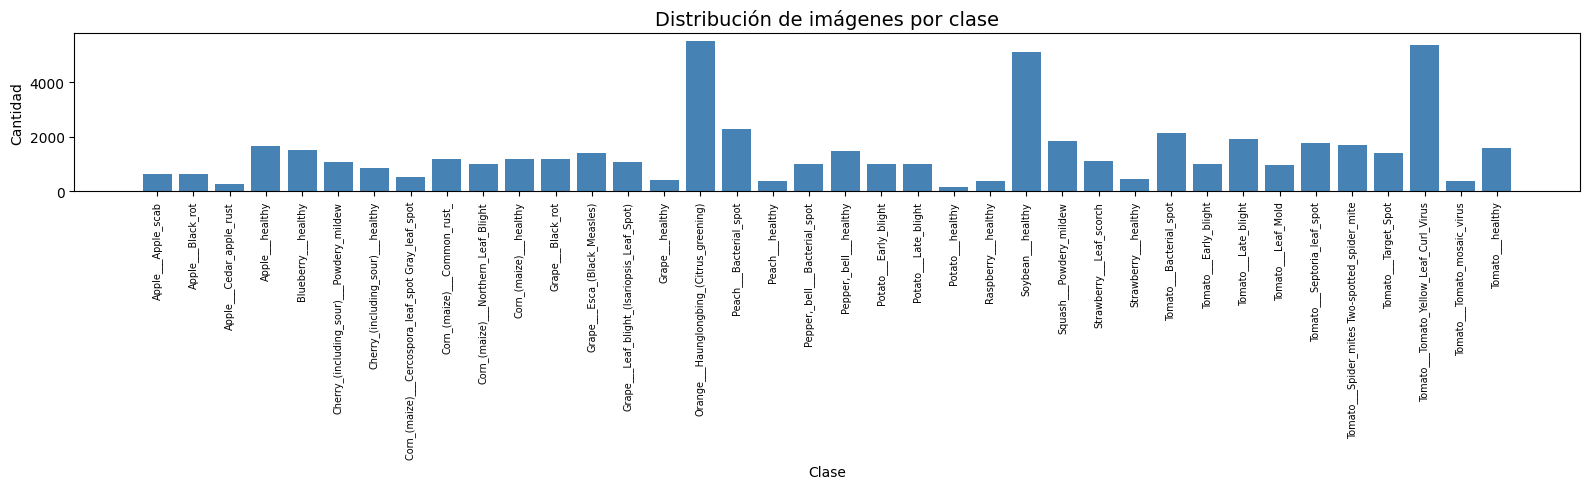


Ratio de desbalance: 36.2:1


In [8]:
# Contar imágenes por clase
class_counts = {}
for class_name in sorted(os.listdir(data_dir)):
    class_path = os.path.join(data_dir, class_name)
    if os.path.isdir(class_path):
        count = len([f for f in os.listdir(class_path)
                     if f.lower().endswith(('.jpg','.jpeg','.png'))])
        class_counts[class_name] = count

print(f"Total de clases: {len(class_counts)}")
print(f"Total de imágenes: {sum(class_counts.values())}")
print(f"Clase más grande: {max(class_counts, key=class_counts.get)} ({max(class_counts.values())})")
print(f"Clase más pequeña: {min(class_counts, key=class_counts.get)} ({min(class_counts.values())})")

# Visualizar distribución
plt.figure(figsize=(16, 5))
plt.bar(range(len(class_counts)), class_counts.values(), color='steelblue')
plt.title('Distribución de imágenes por clase', fontsize=14)
plt.xlabel('Clase')
plt.ylabel('Cantidad')
plt.xticks(range(len(class_counts)), class_counts.keys(), rotation=90, fontsize=7)
plt.tight_layout()
plt.show()

# Ratio de desbalance
max_c = max(class_counts.values())
min_c = min(class_counts.values())
print(f"\nRatio de desbalance: {max_c/min_c:.1f}:1")

### 2.2 Propiedades de las Imágenes

In [9]:
# Analizar propiedades de una muestra de imágenes
widths, heights, channels = [], [], []
sample_classes = list(class_counts.keys())[:5]

for class_name in sample_classes:
    class_path = os.path.join(data_dir, class_name)
    for img_name in os.listdir(class_path)[:50]:
        try:
            img = Image.open(os.path.join(class_path, img_name))
            widths.append(img.width)
            heights.append(img.height)
            channels.append(len(img.getbands()))
        except:
            pass

print(f"Ancho: [{min(widths)}, {max(widths)}], promedio: {np.mean(widths):.0f}")
print(f"Alto: [{min(heights)}, {max(heights)}], promedio: {np.mean(heights):.0f}")
print(f"Canales: {Counter(channels)}")
print(f"Aspecto promedio: {np.mean(widths)/np.mean(heights):.2f}")

Ancho: [256, 256], promedio: 256
Alto: [256, 256], promedio: 256
Canales: Counter({3: 250})
Aspecto promedio: 1.00


### 2.3 Visualización de Muestras

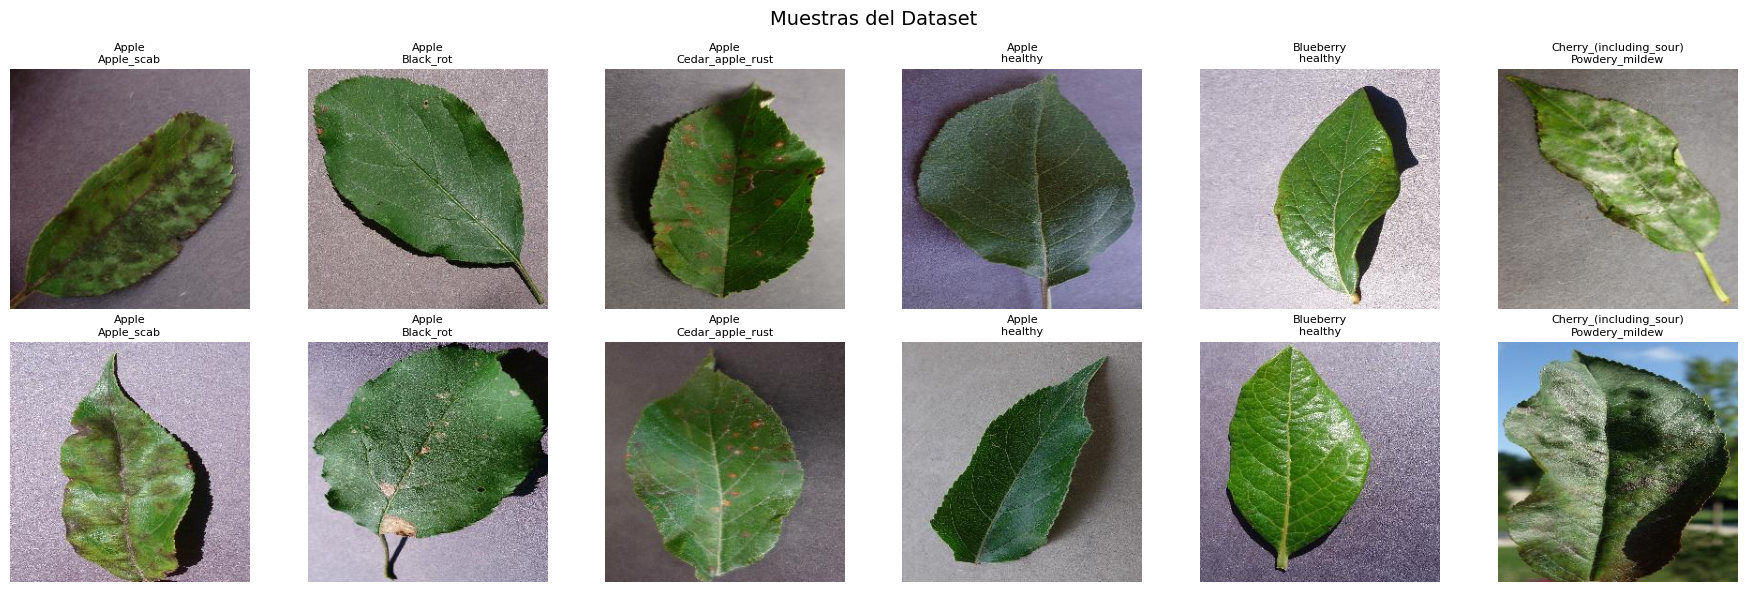

In [10]:
# Mostrar 2 imágenes por clase (primeras 6 clases)
fig, axes = plt.subplots(2, 6, figsize=(18, 6))
class_names_sorted = sorted(class_counts.keys())

for i, class_name in enumerate(class_names_sorted[:6]):
    class_path = os.path.join(data_dir, class_name)
    imgs = os.listdir(class_path)[:2]
    for j, img_name in enumerate(imgs):
        img = Image.open(os.path.join(class_path, img_name))
        axes[j, i].imshow(img)
        axes[j, i].set_title(class_name.replace('___', '\n'), fontsize=8)
        axes[j, i].axis('off')

plt.suptitle('Muestras del Dataset', fontsize=14)
plt.tight_layout()
plt.show()

### 2.4 Detección de Imágenes Corruptas

In [11]:
def find_corrupted_images(directory):
    corrupted = []
    total = 0
    for root, dirs, files in os.walk(directory):
        for fname in files:
            if not fname.lower().endswith(('.jpg','.jpeg','.png')):
                continue
            fpath = os.path.join(root, fname)
            total += 1
            try:
                img = Image.open(fpath)
                img.verify()
            except Exception as e:
                corrupted.append((fpath, str(e)))
    return corrupted, total

corrupted, total = find_corrupted_images(data_dir)
print(f"Imágenes analizadas: {total}")
print(f"Imágenes corruptas: {len(corrupted)} ({len(corrupted)/total*100:.2f}%)")
if corrupted:
    for path, err in corrupted[:5]:
        print(f"  ❌ {path}: {err}")

Imágenes analizadas: 54305
Imágenes corruptas: 0 (0.00%)


---
## 🔄 Fase 3: Preprocesamiento y Data Augmentation

In [12]:
# Pipeline con tf.data (recomendado)
train_dataset = tf.keras.utils.image_dataset_from_directory(
    data_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    seed=SEED, shuffle=True, label_mode='categorical',
    validation_split=0.2, subset='training'
)
val_dataset = tf.keras.utils.image_dataset_from_directory(
    data_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    seed=SEED, shuffle=False, label_mode='categorical',
    validation_split=0.2, subset='validation'
)

class_names = train_dataset.class_names
NUM_CLASSES = len(class_names)
print(f"Clases: {NUM_CLASSES}")
print(f"Primeras 5: {class_names[:5]}")

Found 54305 files belonging to 38 classes.
Using 43444 files for training.
Found 54305 files belonging to 38 classes.
Using 10861 files for validation.
Clases: 38
Primeras 5: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy']


In [13]:
# Capas de augmentation y normalización
normalization = tf.keras.layers.Rescaling(1./255)

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
], name='data_augmentation')

# Aplicar al dataset
def preprocess_train(images, labels):
    images = normalization(images)
    images = data_augmentation(images, training=True)
    return images, labels

def preprocess_val(images, labels):
    images = normalization(images)
    return images, labels

# ⚠️ IMPORTANTE: Augmentation SOLO en entrenamiento
train_ds = train_dataset.map(preprocess_train, num_parallel_calls=tf.data.AUTOTUNE)
train_ds = train_ds.shuffle(1000).prefetch(tf.data.AUTOTUNE)

val_ds = val_dataset.map(preprocess_val, num_parallel_calls=tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)

print("✅ Pipelines de datos configurados")
print(f"  Train: CON augmentation")
print(f"  Val:   SIN augmentation")

✅ Pipelines de datos configurados
  Train: CON augmentation
  Val:   SIN augmentation


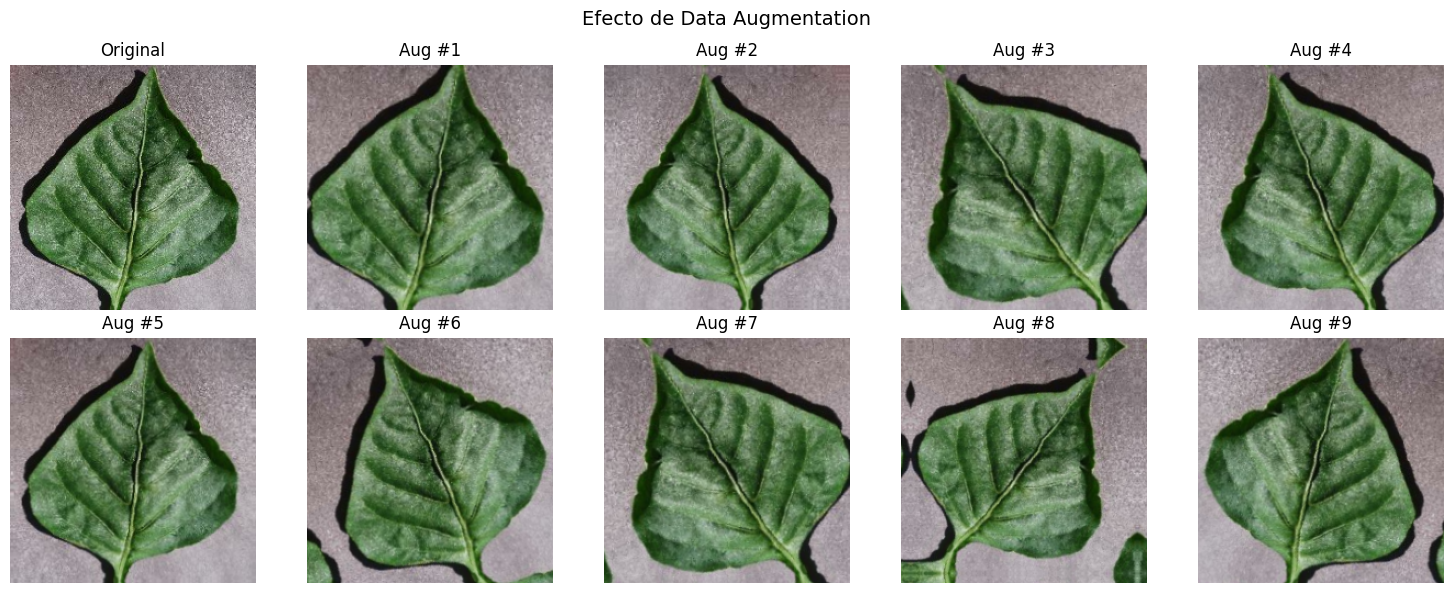

In [14]:
# Visualizar augmentation
sample_batch = next(iter(train_dataset))
sample_img = sample_batch[0][0:1]  # Primera imagen, sin normalizar

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes[0, 0].imshow(sample_img[0].numpy().astype('uint8'))
axes[0, 0].set_title('Original')
axes[0, 0].axis('off')

for i in range(1, 10):
    row, col = i // 5, i % 5
    augmented = data_augmentation(sample_img, training=True)
    axes[row, col].imshow(augmented[0].numpy().clip(0, 255).astype('uint8'))
    axes[row, col].set_title(f'Aug #{i}')
    axes[row, col].axis('off')

plt.suptitle('Efecto de Data Augmentation', fontsize=14)
plt.tight_layout()
plt.show()

---
## 🏗️ Fase 4: Diseño de 3 Modelos CNN

### Modelo 1: CNN Baseline
Arquitectura simple con 3 bloques Conv+BN+ReLU+MaxPool.

In [15]:
def build_baseline_model(input_shape, num_classes):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=input_shape),
        # Bloque 1
        tf.keras.layers.Conv2D(32, (3,3), padding='same'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Activation('relu'),
        tf.keras.layers.MaxPooling2D((2,2)),
        # Bloque 2
        tf.keras.layers.Conv2D(64, (3,3), padding='same'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Activation('relu'),
        tf.keras.layers.MaxPooling2D((2,2)),
        # Bloque 3
        tf.keras.layers.Conv2D(128, (3,3), padding='same'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Activation('relu'),
        tf.keras.layers.GlobalAveragePooling2D(),
        # Clasificador
        tf.keras.layers.Dense(256, activation='relu'),
        tf.keras.layers.Dropout(0.5),
        tf.keras.layers.Dense(num_classes, activation='softmax')
    ], name='cnn_baseline')
    return model

model_baseline = build_baseline_model((*IMG_SIZE, 3), NUM_CLASSES)
model_baseline.summary()

Model: "cnn_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 38)             │         9,766 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 136,934 (534.90 KB)

 Trainable params: 136,486 (533.15 KB)

 Non-trainable params: 448 (1.75 KB)

### Modelo 2: CNN Mejorada con Bloques Residuales
Aplica skip connections (S05) con Functional API.

In [16]:
def residual_block(x, filters, stride=1):
    shortcut = x
    # Rama principal
    x = tf.keras.layers.Conv2D(filters, (3,3), strides=stride, padding='same')(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.Conv2D(filters, (3,3), padding='same')(x)
    x = tf.keras.layers.BatchNormalization()(x)
    # Ajustar shortcut si cambian dimensiones
    if stride != 1 or shortcut.shape[-1] != filters:
        shortcut = tf.keras.layers.Conv2D(filters, (1,1), strides=stride, padding='same')(shortcut)
        shortcut = tf.keras.layers.BatchNormalization()(shortcut)
    x = tf.keras.layers.Add()([x, shortcut])
    x = tf.keras.layers.Activation('relu')(x)
    return x

def build_improved_model(input_shape, num_classes):
    inputs = tf.keras.layers.Input(shape=input_shape)
    # Stem
    x = tf.keras.layers.Conv2D(64, (7,7), strides=2, padding='same')(inputs)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.MaxPooling2D((3,3), strides=2, padding='same')(x)
    # Bloques residuales
    x = residual_block(x, 64)
    x = residual_block(x, 64)
    x = residual_block(x, 128, stride=2)
    x = residual_block(x, 128)
    x = residual_block(x, 256, stride=2)
    x = residual_block(x, 256)
    # Clasificador
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(512, kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.Dropout(0.5)(x)
    outputs = tf.keras.layers.Dense(num_classes, activation='softmax')(x)
    return tf.keras.Model(inputs, outputs, name='cnn_improved')

model_improved = build_improved_model((*IMG_SIZE, 3), NUM_CLASSES)
model_improved.summary()

Model: "cnn_improved"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 112, 112,  │      9,472 │ input_layer_2[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 56, 56,    │          0 │ activation_3[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 56, 56,    │     36,928 │ max_pooling2d_2[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 56, 56,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 56, 56,    │     36,928 │ activation_4[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_5[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 56, 56,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │ max_pooling2d_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_5        │ (None, 56, 56,    │          0 │ add[0][0]         │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 56, 56,    │     36,928 │ activation_5[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_6[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_6        │ (None, 56, 56,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 56, 56,    │     36,928 │ activation_6[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_7[0][0]  

 Total params: 2,942,630 (11.23 MB)

 Trainable params: 2,937,126 (11.20 MB)

 Non-trainable params: 5,504 (21.50 KB)

### Modelo 3: CNN Optimizada
Augmentation integrado + regularización L2 + doble dropout.

In [17]:
def build_optimized_model(input_shape, num_classes):
    inputs = tf.keras.layers.Input(shape=input_shape)
    # Augmentation dentro del modelo (solo activo en training)
    x = tf.keras.layers.RandomFlip("horizontal")(inputs)
    x = tf.keras.layers.RandomRotation(0.1)(x)
    x = tf.keras.layers.RandomZoom(0.1)(x)
    # Stem con L2
    x = tf.keras.layers.Conv2D(64, (7,7), strides=2, padding='same',
                                kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.MaxPooling2D((3,3), strides=2, padding='same')(x)
    # Bloques residuales
    for filters in [64, 64, 128, 128, 256, 256]:
        stride = 2 if (filters != 64 and x.shape[-1] != filters) else 1
        x = residual_block(x, filters, stride)
    # Clasificador con doble dropout
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(512, kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.Dropout(0.5)(x)
    x = tf.keras.layers.Dense(256, kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    outputs = tf.keras.layers.Dense(num_classes, activation='softmax')(x)
    return tf.keras.Model(inputs, outputs, name='cnn_optimized')

model_optimized = build_optimized_model((*IMG_SIZE, 3), NUM_CLASSES)
model_optimized.summary()

Model: "cnn_optimized"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_flip_1       │ (None, 224, 224,  │          0 │ input_layer_3[0]… │
│ (RandomFlip)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_rotation_1   │ (None, 224, 224,  │          0 │ random_flip_1[0]… │
│ (RandomRotation)    │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_zoom_1       │ (None, 224, 224,  │          0 │ random_rotation_… │
│ (RandomZoom)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_18 (Conv2D)  │ (None, 112, 112,  │      9,472 │ random_zoom_1[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        256 │ conv2d_18[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_17       │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 56, 56,    │          0 │ activation_17[0]… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 56, 56,    │     36,928 │ max_pooling2d_3[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_19[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_18       │ (None, 56, 56,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_20 (Conv2D)  │ (None, 56, 56,    │     36,928 │ activation_18[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_20[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_6 (Add)         │ (None, 56, 56,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │ max_pooling2d_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_19       │ (None, 56, 56,    │          0 │ add_6[0][0]       │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 56, 56,    │     36,928 │ activation_19[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_21[0][0] 

 Total params: 3,064,230 (11.69 MB)

 Trainable params: 3,058,726 (11.67 MB)

 Non-trainable params: 5,504 (21.50 KB)

In [18]:
# Comparar los 3 modelos
print(f"{'Modelo':<25} {'Params':>12} {'Tamaño (MB)':>12}")
print("-" * 50)
for name, m in [("CNN Baseline", model_baseline),
                ("CNN Mejorada", model_improved),
                ("CNN Optimizada", model_optimized)]:
    params = m.count_params()
    size_mb = params * 4 / 1024 / 1024
    print(f"{name:<25} {params:>12,} {size_mb:>10.1f} MB")

Modelo                          Params  Tamaño (MB)
--------------------------------------------------
CNN Baseline                   136,934        0.5 MB
CNN Mejorada                 2,942,630       11.2 MB
CNN Optimizada               3,064,230       11.7 MB


---
## 🏋️ Fase 5: Entrenamiento con Callbacks Profesionales

Entrenaremos los 3 modelos para comparar. Empezamos con el Baseline.

In [19]:
# Configuración centralizada
CONFIG = {
    'learning_rate': 1e-3,
    'epochs': 50,
    'batch_size': BATCH_SIZE,
    'weight_decay': 1e-4,
    'label_smoothing': 0.1,
}

def train_model(model, train_ds, val_ds, config, experiment_name):
    """Entrena un modelo con configuración profesional."""
    log_dir = f"logs/{experiment_name}"
    checkpoint_dir = f"checkpoints/{experiment_name}"
    os.makedirs(log_dir, exist_ok=True)
    os.makedirs(checkpoint_dir, exist_ok=True)

    # Guardar configuración
    with open(f"{log_dir}/config.json", 'w') as f:
        json.dump(config, f, indent=2)

    # Compilar
    optimizer = tf.keras.optimizers.Adam(
        learning_rate=config['learning_rate'],
        weight_decay=config['weight_decay']
    )
    loss_fn = tf.keras.losses.CategoricalCrossentropy(
        label_smoothing=config['label_smoothing']
    )
    model.compile(optimizer=optimizer, loss=loss_fn,
                  metrics=['accuracy', tf.keras.metrics.AUC(name='auc')])

    # Callbacks
    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(
            f"{checkpoint_dir}/best_model.keras",
            monitor='val_accuracy', mode='max', save_best_only=True, verbose=1),
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=10, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6, verbose=1),
        tf.keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1),
        tf.keras.callbacks.CSVLogger(f"{log_dir}/training_log.csv"),
    ]

    # Entrenar
    history = model.fit(train_ds, validation_data=val_ds,
                        epochs=config['epochs'], callbacks=callbacks, verbose=1)
    return history, log_dir, checkpoint_dir

print("✅ Función de entrenamiento definida")

✅ Función de entrenamiento definida


In [ ]:
# Entrenar Modelo 1: Baseline
timestamp = datetime.datetime.now().strftime('%Y%m%d_%H%M%S')
history_baseline, log_baseline, ckpt_baseline = train_model(
    model_baseline, train_ds, val_ds, CONFIG, f"baseline_{timestamp}"
)

Epoch 1/50


In [ ]:
# Entrenar Modelo 2: Mejorada
history_improved, log_improved, ckpt_improved = train_model(
    model_improved, train_ds, val_ds, CONFIG, f"improved_{timestamp}"
)

In [ ]:
# Entrenar Modelo 3: Optimizada
# Nota: este modelo tiene augmentation interno, pero el pipeline ya normaliza.
# Para evitar doble augmentation, usar val_ds para ambos (que ya NO tiene aug).
# O crear un pipeline sin aug para train_ds del modelo optimizado.

history_optimized, log_optimized, ckpt_optimized = train_model(
    model_optimized, train_ds, val_ds, CONFIG, f"optimized_{timestamp}"
)

### 5.1 Visualizar Curvas de Aprendizaje

In [ ]:
def plot_training_history(history, title="", save_path=None):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # Loss
    axes[0].plot(history.history['loss'], label='Train', linewidth=2)
    axes[0].plot(history.history['val_loss'], label='Val', linewidth=2)
    axes[0].set_title('Loss'); axes[0].set_xlabel('Época')
    axes[0].legend(); axes[0].grid(True, alpha=0.3)

    # Accuracy
    axes[1].plot(history.history['accuracy'], label='Train', linewidth=2)
    axes[1].plot(history.history['val_accuracy'], label='Val', linewidth=2)
    axes[1].set_title('Accuracy'); axes[1].set_xlabel('Época')
    axes[1].legend(); axes[1].grid(True, alpha=0.3)

    # Learning Rate
    if 'lr' in history.history:
        axes[2].plot(history.history['lr'], linewidth=2, color='green')
        axes[2].set_title('Learning Rate'); axes[2].set_xlabel('Época')
        axes[2].set_yscale('log'); axes[2].grid(True, alpha=0.3)

    plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()

# Graficar para cada modelo
for name, hist, log_dir in [
    ("CNN Baseline", history_baseline, log_baseline),
    ("CNN Mejorada", history_improved, log_improved),
    ("CNN Optimizada", history_optimized, log_optimized)
]:
    plot_training_history(hist, title=name, save_path=f"{log_dir}/training_curves.png")

### 📝 Pregunta de Análisis
Observe las curvas de los 3 modelos. ¿Cuál muestra mejor ajuste? ¿Alguno presenta overfitting?

*TODO: Escriba su análisis aquí*

---
## 📊 Fase 6: Suite de Evaluación Completa

Evaluaremos el **mejor modelo** (CNN Optimizada) con la suite profesional.

In [ ]:
# Obtener predicciones
# Usamos el mejor modelo (optimizado)
model = model_optimized

y_pred_probs = model.predict(val_ds)
y_pred = np.argmax(y_pred_probs, axis=1)

# Obtener etiquetas reales
y_true = np.concatenate([np.argmax(y, axis=1) for _, y in val_ds])

print(f"Predicciones: {len(y_pred)}")
print(f"Etiquetas reales: {len(y_true)}")

### 6.1 Classification Report

In [ ]:
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

### 6.2 Matriz de Confusión Profesional

In [ ]:
def plot_confusion_matrix(y_true, y_pred, class_names, save_path=None):
    cm = confusion_matrix(y_true, y_pred)
    cm_pct = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

    fig, axes = plt.subplots(1, 2, figsize=(24, 10))

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names, ax=axes[0])
    axes[0].set_title('Matriz de Confusión — Conteos', fontsize=13)
    axes[0].set_ylabel('Clase Real'); axes[0].set_xlabel('Clase Predicha')
    axes[0].tick_params(axis='both', labelsize=6)

    sns.heatmap(cm_pct, annot=True, fmt='.1f', cmap='Oranges',
                xticklabels=class_names, yticklabels=class_names, ax=axes[1])
    axes[1].set_title('Matriz de Confusión — Porcentaje (%)', fontsize=13)
    axes[1].set_ylabel('Clase Real'); axes[1].set_xlabel('Clase Predicha')
    axes[1].tick_params(axis='both', labelsize=6)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()

plot_confusion_matrix(y_true, y_pred, class_names, f"{log_optimized}/confusion_matrix.png")

### 6.3 Curvas ROC Multiclase

In [ ]:
def plot_roc_curves(y_true, y_pred_probs, class_names, save_path=None):
    n_classes = len(class_names)
    y_true_bin = label_binarize(y_true, classes=range(n_classes))

    fig, ax = plt.subplots(figsize=(10, 8))

    # Graficar las primeras 10 clases (legibilidad)
    for i in range(min(n_classes, 10)):
        fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_pred_probs[:, i])
        roc_auc = auc(fpr, tpr)
        ax.plot(fpr, tpr, linewidth=2,
                label=f'{class_names[i][:20]} (AUC={roc_auc:.3f})')

    ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random')
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title('Curvas ROC por Clase (primeras 10)')
    ax.legend(loc='lower right', fontsize=8)
    ax.grid(True, alpha=0.3)

    # Macro AUC
    macro_auc = roc_auc_score(y_true_bin, y_pred_probs, multi_class='ovr', average='macro')
    ax.text(0.55, 0.15, f'Macro AUC: {macro_auc:.4f}', fontsize=14,
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    return macro_auc

macro_auc = plot_roc_curves(y_true, y_pred_probs, class_names, f"{log_optimized}/roc_curves.png")
print(f"Macro AUC: {macro_auc:.4f}")

---
## 🔬 Fase 7: Análisis de Errores

In [ ]:
def analyze_top_errors(y_true, y_pred, class_names, top_k=10):
    cm = confusion_matrix(y_true, y_pred)
    np.fill_diagonal(cm, 0)

    errors = []
    for i in range(len(class_names)):
        for j in range(len(class_names)):
            if cm[i, j] > 0:
                errors.append({
                    'real': class_names[i],
                    'predicha': class_names[j],
                    'count': cm[i, j]
                })

    errors.sort(key=lambda x: x['count'], reverse=True)

    print(f"{'Real':<30} {'Predicha':<30} {'Errores':>8}")
    print("=" * 70)
    for err in errors[:top_k]:
        print(f"{err['real']:<30} {err['predicha']:<30} {err['count']:>8}")

    return errors[:top_k]

top_errors = analyze_top_errors(y_true, y_pred, class_names)

### 📝 Tabla de Mejoras
Basándose en los errores encontrados, complete:

| Hallazgo | Acción correctiva propuesta |
|---|---|
| *TODO: Par confundido 1* | *TODO: Propuesta* |
| *TODO: Par confundido 2* | *TODO: Propuesta* |
| *TODO: Par confundido 3* | *TODO: Propuesta* |

---
## 📈 Fase 8: Comparación Sistemática de Modelos

In [ ]:
import pandas as pd

results = []
for name, model, history in [
    ("CNN Baseline", model_baseline, history_baseline),
    ("CNN Mejorada", model_improved, history_improved),
    ("CNN Optimizada", model_optimized, history_optimized)
]:
    best_val_acc = max(history.history['val_accuracy'])
    best_val_loss = min(history.history['val_loss'])
    total_epochs = len(history.history['loss'])
    params = model.count_params()

    results.append({
        'Modelo': name,
        'Val Accuracy': f"{best_val_acc:.4f}",
        'Val Loss': f"{best_val_loss:.4f}",
        'Parámetros': f"{params:,}",
        'Épocas': total_epochs,
        'Tamaño (MB)': f"{params*4/1024/1024:.1f}",
    })

df_results = pd.DataFrame(results)
print(df_results.to_string(index=False))

In [ ]:
# Gráfico de barras comparativo
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
model_names = [r['Modelo'] for r in results]
accuracies = [float(r['Val Accuracy']) for r in results]
params_m = [int(r['Parámetros'].replace(',','')) / 1e6 for r in results]

axes[0].bar(model_names, accuracies, color=['#2196F3', '#4CAF50', '#FF9800'])
axes[0].set_title('Val Accuracy por Modelo')
axes[0].set_ylim([min(accuracies)-0.05, 1.0])
axes[0].grid(True, alpha=0.3, axis='y')
for i, v in enumerate(accuracies):
    axes[0].text(i, v + 0.005, f'{v:.3f}', ha='center', fontweight='bold')

# Trade-off scatter
axes[1].scatter(params_m, accuracies, s=200, c=['#2196F3', '#4CAF50', '#FF9800'], zorder=5)
for i, name in enumerate(model_names):
    axes[1].annotate(name.replace('CNN ', ''), (params_m[i], accuracies[i]),
                     textcoords="offset points", xytext=(10, 5), fontsize=9)
axes[1].set_xlabel('Parámetros (M)')
axes[1].set_ylabel('Val Accuracy')
axes[1].set_title('Trade-off: Rendimiento vs Complejidad')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f"{log_optimized}/model_comparison.png", dpi=150, bbox_inches='tight')
plt.show()

### 📝 Pregunta de Producción
¿Cuál modelo seleccionaría para producción si el requisito es < 10 MB para móviles?

*TODO: Justifique cuantitativamente*

---
## 💾 Fases 9-11: Versionado, Logging y Documentación

In [ ]:
def save_model_metadata(model, history, config, dataset_info, save_path):
    metadata = {
        'version': '1.0',
        'timestamp': datetime.datetime.now().isoformat(),
        'model': {
            'architecture': model.name,
            'total_params': model.count_params(),
            'input_shape': list(model.input_shape[1:]),
            'output_classes': model.output_shape[-1],
        },
        'training': {
            'config': config,
            'best_val_accuracy': float(max(history.history['val_accuracy'])),
            'best_val_loss': float(min(history.history['val_loss'])),
            'final_epoch': len(history.history['loss']),
        },
        'dataset': dataset_info,
        'environment': {
            'tensorflow': tf.__version__,
            'python': platform.python_version(),
            'gpu': str(tf.config.list_physical_devices('GPU')),
        }
    }
    with open(save_path, 'w') as f:
        json.dump(metadata, f, indent=2, default=str)
    print(f"✅ Metadata guardada: {save_path}")
    return metadata

# Guardar metadata del mejor modelo
metadata = save_model_metadata(
    model_optimized, history_optimized, CONFIG,
    {'name': 'PlantVillage', 'classes': NUM_CLASSES,
     'total': sum(class_counts.values())},
    f"{ckpt_optimized}/metadata.json"
)
print(json.dumps(metadata, indent=2))

---
## 🚀 Fase 12: Despliegue Básico

In [ ]:
# Guardar modelo final
os.makedirs('models/production', exist_ok=True)
model_optimized.save('models/production/model_v1.keras')
print("✅ Modelo guardado: models/production/model_v1.keras")

# Verificar carga
loaded_model = tf.keras.models.load_model('models/production/model_v1.keras')
test_loss, test_acc, test_auc = loaded_model.evaluate(val_ds, verbose=0)
print(f"\nModelo cargado — Val accuracy: {test_acc:.4f}, Val AUC: {test_auc:.4f}")

### 12.1 Conversión a TFLite

In [ ]:
def convert_to_tflite(keras_path, output_path, quantize=False):
    model = tf.keras.models.load_model(keras_path)
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    if quantize:
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
        converter.target_spec.supported_types = [tf.float16]
    tflite_model = converter.convert()
    with open(output_path, 'wb') as f:
        f.write(tflite_model)

    orig_size = os.path.getsize(keras_path) / (1024 * 1024)
    lite_size = os.path.getsize(output_path) / (1024 * 1024)
    reduction = (1 - lite_size / orig_size) * 100
    print(f"Original: {orig_size:.1f} MB → TFLite: {lite_size:.1f} MB ({reduction:.0f}% reducción)")
    return lite_size

# Sin cuantización
convert_to_tflite('models/production/model_v1.keras', 'models/production/model_v1.tflite')
# Con cuantización float16
convert_to_tflite('models/production/model_v1.keras', 'models/production/model_v1_q.tflite', quantize=True)

### 12.2 Script de Predicción

In [ ]:
def predict_image(model_path, image_path, class_names, img_size=(224, 224)):
    model = tf.keras.models.load_model(model_path)
    img = tf.keras.preprocessing.image.load_img(image_path, target_size=img_size)
    img_array = tf.keras.preprocessing.image.img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    preds = model.predict(img_array, verbose=0)
    predicted = class_names[np.argmax(preds[0])]
    conf = np.max(preds[0])

    # Top 3
    top3_idx = np.argsort(preds[0])[-3:][::-1]
    print(f"Predicción: {predicted} ({conf:.1%})")
    for idx in top3_idx:
        print(f"  {class_names[idx]}: {preds[0][idx]:.1%}")

    # Visualizar
    plt.figure(figsize=(6, 6))
    plt.imshow(tf.keras.preprocessing.image.load_img(image_path, target_size=img_size))
    plt.title(f"Predicción: {predicted} ({conf:.1%})", fontsize=12)
    plt.axis('off')
    plt.show()

    return predicted, conf

# Ejemplo: predecir una imagen del dataset
sample_class = class_names[0]
sample_dir = os.path.join(data_dir, sample_class)
sample_img = os.path.join(sample_dir, os.listdir(sample_dir)[0])
predict_image('models/production/model_v1.keras', sample_img, class_names)

---
## ✅ Checklist del Pipeline Completo

| # | Fase | Estado |
|---|---|---|
| 1 | Definición del problema | ☐ |
| 2 | Selección del dataset + EDA | ☐ |
| 3 | Preprocesamiento + augmentation | ☐ |
| 4 | 3 modelos CNN (Baseline, Mejorada, Optimizada) | ☐ |
| 5 | Entrenamiento con 5 callbacks | ☐ |
| 6 | Evaluación (report + confusión + ROC) | ☐ |
| 7 | Análisis de errores | ☐ |
| 8 | Comparación de modelos | ☐ |
| 9 | Versionado y metadata | ☐ |
| 10 | Logging (CSVLogger + TensorBoard) | ☐ |
| 11 | Documentación (reporte técnico) | ☐ |
| 12 | Despliegue (export + TFLite) | ☐ |

---

### 📝 Reporte Técnico Breve
*Escriba aquí su reporte:*

**Resumen ejecutivo:** *TODO*

**Dataset:** *TODO*

**Resultados principales:** *TODO*

**Análisis de errores:** *TODO*

**Conclusiones y trabajo futuro:** *TODO*

---
> 🎓 **Sesión 08 — Práctica Integradora de Cierre de Unidad I**
> IS056B — Ingeniería del Conocimiento | UNCP 2026-II
> Msc. Jaime Antonio Huaytalla Pariona